<a href="https://colab.research.google.com/github/RahulGupta1291/ml-assignment-2/blob/main/ML_2026AJ05022_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 — AIMLZG565 — Machine Learning

**WILP Division**
**M. Tech. in Artificial Intelligence & Machine Learning**
**I Semester 2026-27**

---

**Assignment II**

**Student Name:** RAHUL GUPTA
**BITS ID:** 2026AJ05022
**Semester:** 1st (2026-27)

---

## Multi Model Classification and App Deployment

### Problem statement
In this assignment, we have to implement the following:
- Implement multiple classification models
- Build an interactive Streamlit web application to demonstrate your models
- Deploy the app on Streamlit Community Cloud (FREE)
---

## Dataset Used
Heart Disease Prediction Dataset 2026

https://www.kaggle.com/datasets/mohankrishnathalla/heart-disease-prediction-dataset-2026


In [1]:
from google.colab import drive
drive.mount('/content/drive')
from google.colab import files

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import math

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay
)

np.random.seed(12)

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.autolayout": True, "axes.titleweight": "bold"})
plt.rcParams['axes.grid'] = False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading the data

In [2]:
train  = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/heart_disease_train.csv')
test   = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/heart_disease_test.csv')

for name, df in [("bike_train", train), ("bike_test", test)]:
    print(f"Dataset: {name:18s} \nShape: {str(df.shape):12s} \nColoumns: {list(df.columns)}\n\n")

Dataset: bike_train         
Shape: (1800, 26)   
Coloumns: ['age', 'sex', 'bmi', 'region', 'income_level', 'smoking_status', 'alcohol_intake', 'physical_activity', 'diet_quality', 'sleep_hours', 'stress_level', 'diabetes', 'hypertension', 'family_history', 'previous_heart_event', 'resting_bp', 'cholesterol', 'fasting_blood_sugar', 'max_heart_rate', 'resting_ecg', 'exercise_angina', 'st_depression', 'st_slope', 'avg_resting_hr', 'hrv_score', 'heart_disease']


Dataset: bike_test          
Shape: (200, 26)    
Coloumns: ['age', 'sex', 'bmi', 'region', 'income_level', 'smoking_status', 'alcohol_intake', 'physical_activity', 'diet_quality', 'sleep_hours', 'stress_level', 'diabetes', 'hypertension', 'family_history', 'previous_heart_event', 'resting_bp', 'cholesterol', 'fasting_blood_sugar', 'max_heart_rate', 'resting_ecg', 'exercise_angina', 'st_depression', 'st_slope', 'avg_resting_hr', 'hrv_score', 'heart_disease']




In [3]:
# ------ Printing first 5 rows of the datasets to view the columns and entry type ------
print("irst 5 Rows of Training Dataset:")
display(train.head())
print("\n\nFirst 5 Rows of Test Dataset:")
display(test.head())

irst 5 Rows of Training Dataset:


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,57,Male,27.1,Northeast,Middle,Never,Moderate,Light,7,5.7,...,204,0,195,Normal,0,0.9,Downsloping,61.8,19.9,0
1,40,Female,29.0,Northeast,Low,Never,Non-drinker,Sedentary,1,8.0,...,173,0,165,ST-T Abnormality,0,0.5,Downsloping,53.2,48.3,0
2,63,Female,40.1,Southeast,High,Never,Moderate,Sedentary,6,5.5,...,209,0,173,Normal,0,2.3,Downsloping,82.3,5.0,1
3,66,Female,35.5,West,Middle,Never,Heavy,Sedentary,10,7.4,...,187,0,144,Normal,0,1.3,Downsloping,71.1,38.3,1
4,29,Female,19.8,Northeast,High,Current,Non-drinker,Sedentary,8,8.3,...,247,0,170,ST-T Abnormality,0,0.4,Downsloping,74.1,49.4,0




First 5 Rows of Test Dataset:


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,55,Male,23.0,Midwest,Low,Never,Non-drinker,Sedentary,5,8.3,...,248,0,165,Left Ventricular Hypertrophy,0,0.4,Upsloping,81.9,56.7,0
1,45,Female,31.5,Southeast,Low,Never,Moderate,Light,6,7.2,...,214,1,160,Normal,0,1.0,Upsloping,63.2,76.0,0
2,57,Male,30.8,Southeast,High,Former,Non-drinker,Sedentary,2,6.1,...,183,0,186,ST-T Abnormality,1,1.7,Flat,67.1,52.8,0
3,48,Male,34.0,Northeast,High,Never,Moderate,Active,8,8.9,...,181,1,192,ST-T Abnormality,1,2.7,Flat,57.4,37.8,0
4,29,Male,28.4,Southeast,Middle,Never,Moderate,Light,4,6.8,...,262,1,202,ST-T Abnormality,0,0.2,Downsloping,60.2,50.3,0


## Examine dataset size, missing values, and feature types

In [4]:
print(f"Training set : {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Test set     : {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"Total        : {train.shape[0] + test.shape[0]:,} rows")
print("\n\nInformation about the Current Training dataset:")
train.info()

# ---- Information about missing values in the datasets ----
print("\n\nMissing values in train:", int(train.isna().sum().sum()))
print("Missing values in test :", int(test.isna().sum().sum()))
print("Fully duplicated rows in train:", int(train.duplicated().sum()))

# ---- Numeric analysis of the Target variable ----
y_full = train["heart_disease"].values
print("\n\nNumeric analysis of the Target variable:")
display(train["heart_disease"].describe().to_frame().T)
print(f"skewness of heart_disease        : {train['heart_disease'].skew():.3f}")

# ---- Information about the continous variables in the Train dataset ----
print("\n\nInformation about the continous variables in the Current Training dataset:")
display(train[["age", "bmi", "sleep_hours", "diet_quality", "stress_level", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"]].describe().T)

# ---- Checking balance of the categorical variables in the dataset ----
print("\n\nChecking balance of the categorical variables in the dataset:")
for c in ["sex", "region", "income_level", "smoking_status", "alcohol_intake", "physical_activity", "diabetes", "hypertension", "family_history", "previous_heart_event", "fasting_blood_sugar", "resting_ecg", "exercise_angina", "st_slope"]:
    vc = train[c].value_counts().sort_index()
    print(f"{c:12s}", " | ".join(f"{k}:{v}" for k, v in vc.items()))

Training set : 1,800 rows x 26 columns
Test set     : 200 rows x 26 columns
Total        : 2,000 rows


Information about the Current Training dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1800 non-null   int64  
 1   sex                   1800 non-null   object 
 2   bmi                   1800 non-null   float64
 3   region                1800 non-null   object 
 4   income_level          1800 non-null   object 
 5   smoking_status        1800 non-null   object 
 6   alcohol_intake        1800 non-null   object 
 7   physical_activity     1800 non-null   object 
 8   diet_quality          1800 non-null   int64  
 9   sleep_hours           1800 non-null   float64
 10  stress_level          1800 non-null   int64  
 11  diabetes              1800 non-null   int64  
 12  hypertension          

,count,mean,std,min,25%,50%,75%,max
heart_disease,1800.0,0.440556,0.496592,0.0,0.0,0.0,1.0,1.0


skewness of heart_disease        : 0.240


Information about the continous variables in the Current Training dataset:


,count,mean,std,min,25%,50%,75%,max
age,1800.0,52.672778,12.406140,29.0,44.0,53.0,61.000,80.0
bmi,1800.0,27.925944,5.422336,15.0,24.3,28.1,31.500,46.0
sleep_hours,1800.0,6.917944,1.068751,4.0,6.2,6.9,7.600,10.0
diet_quality,1800.0,5.940556,2.030430,1.0,5.0,6.0,7.000,10.0
stress_level,1800.0,5.767222,2.204834,1.0,4.0,6.0,7.000,10.0
resting_bp,1800.0,140.624444,24.031087,80.0,123.0,141.0,158.000,200.0
cholesterol,1800.0,214.783889,47.523792,100.0,184.0,214.0,246.250,393.0
max_heart_rate,1800.0,174.955000,14.750046,120.0,165.0,175.0,186.000,202.0
st_depression,1800.0,1.357278,1.035110,0.0,0.6,1.1,1.900,6.2
avg_resting_hr,1800.0,69.980222,12.267284,40.0,61.3,70.0,78.125,110.0




Checking balance of the categorical variables in the dataset:
sex          Female:816 | Male:984
region       Midwest:398 | Northeast:329 | Southeast:441 | Southwest:313 | West:319
income_level High:445 | Low:525 | Middle:830
smoking_status Current:244 | Former:439 | Never:1117
alcohol_intake Heavy:256 | Moderate:873 | Non-drinker:671
physical_activity Active:438 | Light:528 | Sedentary:515 | Very Active:319
diabetes     0:1621 | 1:179
hypertension 0:977 | 1:823
family_history 0:1243 | 1:557
previous_heart_event 0:1744 | 1:56
fasting_blood_sugar 0:1553 | 1:247
resting_ecg  Left Ventricular Hypertrophy:351 | Normal:849 | ST-T Abnormality:600
exercise_angina 0:1350 | 1:450
st_slope     Downsloping:336 | Flat:710 | Upsloping:754


**Analysis of Training and Test datasets**

1. **Siz:** The training set has **1,800 rows x 26 columns** and the test set **200 rows x 26 columns**
(2,000 rows in total) and the target is `heart_disease`.

2. **Missing values:** There are **no `NaN` values anywhere** in either file, and no fully duplicated
rows.

3. **Class Balance:** Features such as `sex`, `region`, `income_level`, `physical_activity`, and `hypertension`, are well balanced, but `smoking_status`, `diabetes`, `family_history`, `previous_heart_event`, `fasting_blood_sugar`, and `exercise_angina`, are severely imbalanced.

4. **Feature Reduction:** `region`, `income_level`, `st_slope`, `sleep_hours`,  `diet_quality`, `max_heart_rate`, `fasting_blood_sugar`, `resting_ecg`, and `exercise_angina`, must be dropped as they will not provide concrete information to the prediction and may induce noise.

## Visualize relationships between key features and `heart_disease`

In [5]:
# ---- Define your list of continuous variables ----
continuous_vars = [
    "age", "bmi", "sleep_hours", "diet_quality", "stress_level",
    "resting_bp", "cholesterol", "max_heart_rate",
    "st_depression", "avg_resting_hr", "hrv_score"
]

# 1. Define your list of categorical variables
categorical_vars = [
    "sex", "region", "income_level", "smoking_status", "alcohol_intake",
    "physical_activity", "diabetes", "hypertension", "family_history",
    "previous_heart_event", "fasting_blood_sugar", "resting_ecg",
    "exercise_angina", "st_slope"
]

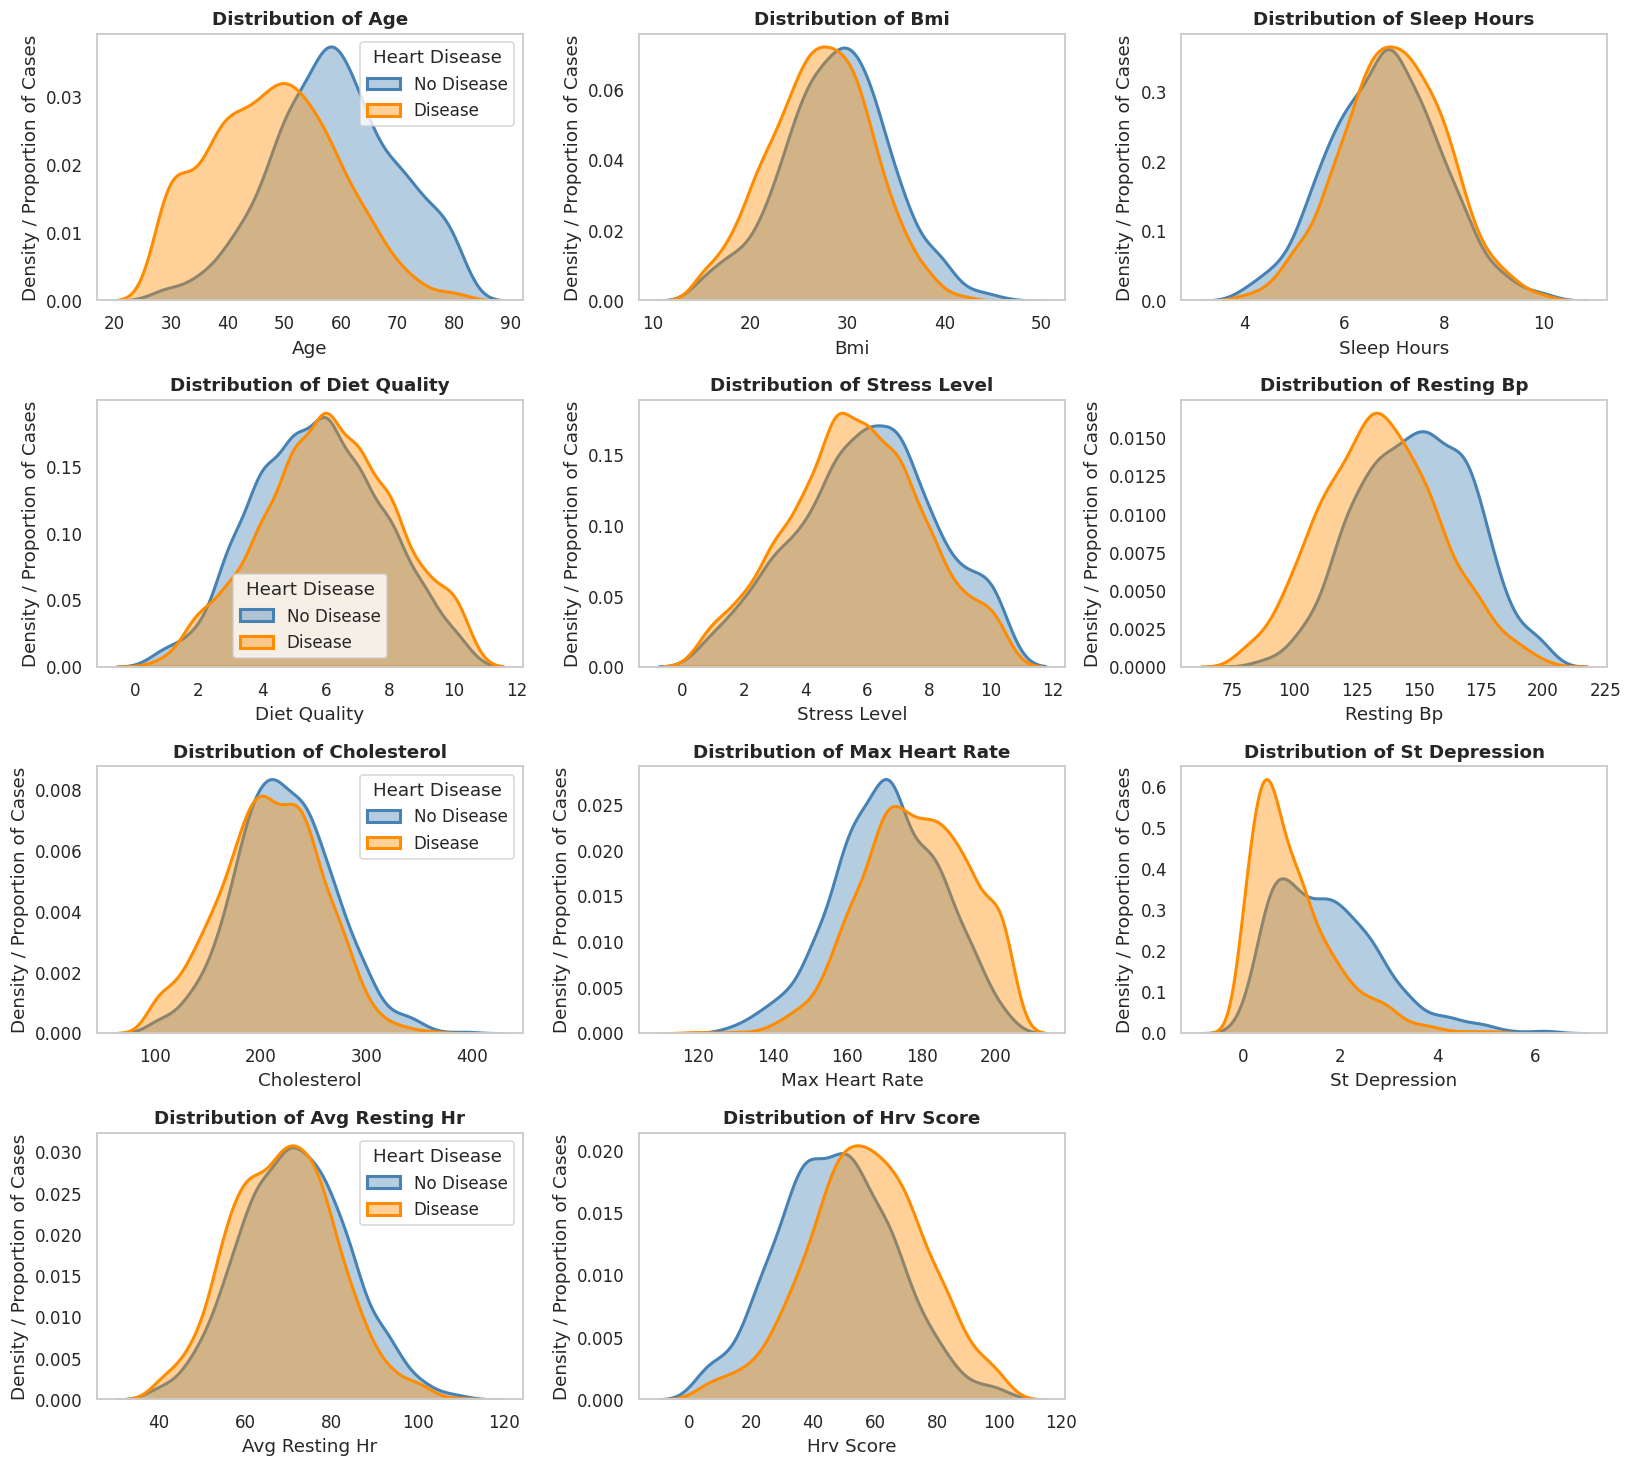

In [6]:
# ---- Initialize the subplot grid ----
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 4.5 * 3))
axes = axes.flatten()

# ---- Loop through each variable and plot the distributions ----
for i, var in enumerate(continuous_vars):
    sns.kdeplot(data=train, x=var, hue="heart_disease", fill=True, common_norm=False, palette={0: "darkorange", 1: "steelblue"}, alpha=0.4, linewidth=2, ax=axes[i])

    axes[i].set_title(f"Distribution of {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Density / Proportion of Cases")

    legend = axes[i].get_legend()
    legend.set_title("Heart Disease")
    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease")
    else:
        axes[i].get_legend().remove()

# ---- Hide the final empty subplot (12th slot) ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

--- Correlation with Heart Disease ---
age               0.4391
st_depression     0.3386
resting_bp        0.2880
bmi               0.1520
cholesterol       0.1365
avg_resting_hr    0.1077
stress_level      0.0780
sleep_hours      -0.0792
diet_quality     -0.0909
hrv_score        -0.2463
max_heart_rate   -0.2599
Name: heart_disease, dtype: float64
---------------------------------------


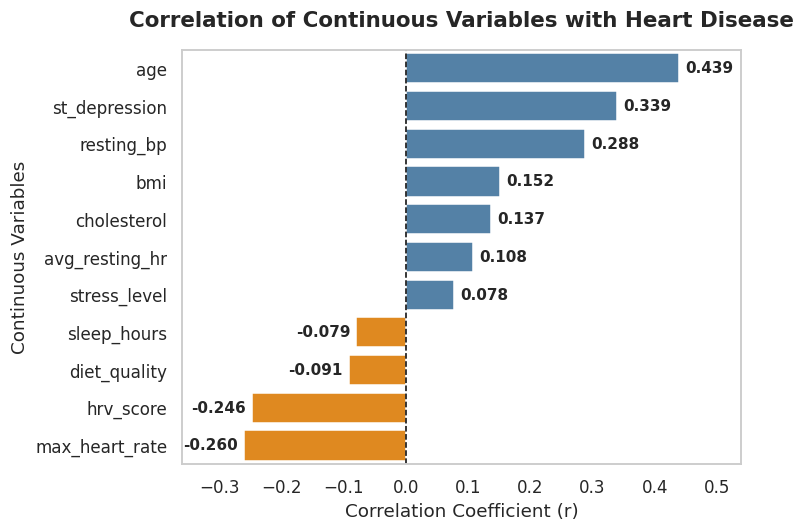

In [7]:
# ---- Add 'heart_disease' to the list to compute the correlation matrix ----
columns_to_analyze = continuous_vars + ["heart_disease"]

# ---- Calculate correlations and isolate the 'heart_disease' column ----
correlation_series = (
    train[columns_to_analyze]
    .corr()["heart_disease"]
    .drop("heart_disease")
    .sort_values(ascending=False)
)

# ---- Print the numeric values in the console  ----
print("--- Correlation with Heart Disease ---")
print(correlation_series.round(4))
print("---------------------------------------")

# ---- Use a diverging color scheme to separate positive and negative trends  ----
plt.figure(figsize=(7, 5))
colors = ['steelblue' if val >= 0 else 'darkorange' for val in correlation_series.values]

sns.barplot(x=correlation_series.values, y=correlation_series.index, palette=colors, hue=correlation_series.index, legend=False)

# ---- Add a vertical line at 0 for visual reference  ----
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

plt.title("Correlation of Continuous Variables with Heart Disease", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Correlation Coefficient (r)")
plt.ylabel("Continuous Variables")

# ---- add text labels on the bars showing the exact value  ----
for index, value in enumerate(correlation_series.values):
    ha_direction = 'left' if value >= 0 else 'right'
    offset = 0.01 if value >= 0 else -0.01
    plt.text(value + offset, index, f"{value:.3f}", va='center', ha=ha_direction, fontweight='bold', fontsize=10)

# ---- Adjust margins so labels don't get cut off  ----
plt.xlim(correlation_series.min() - 0.1, correlation_series.max() + 0.1)
plt.tight_layout()
plt.show()

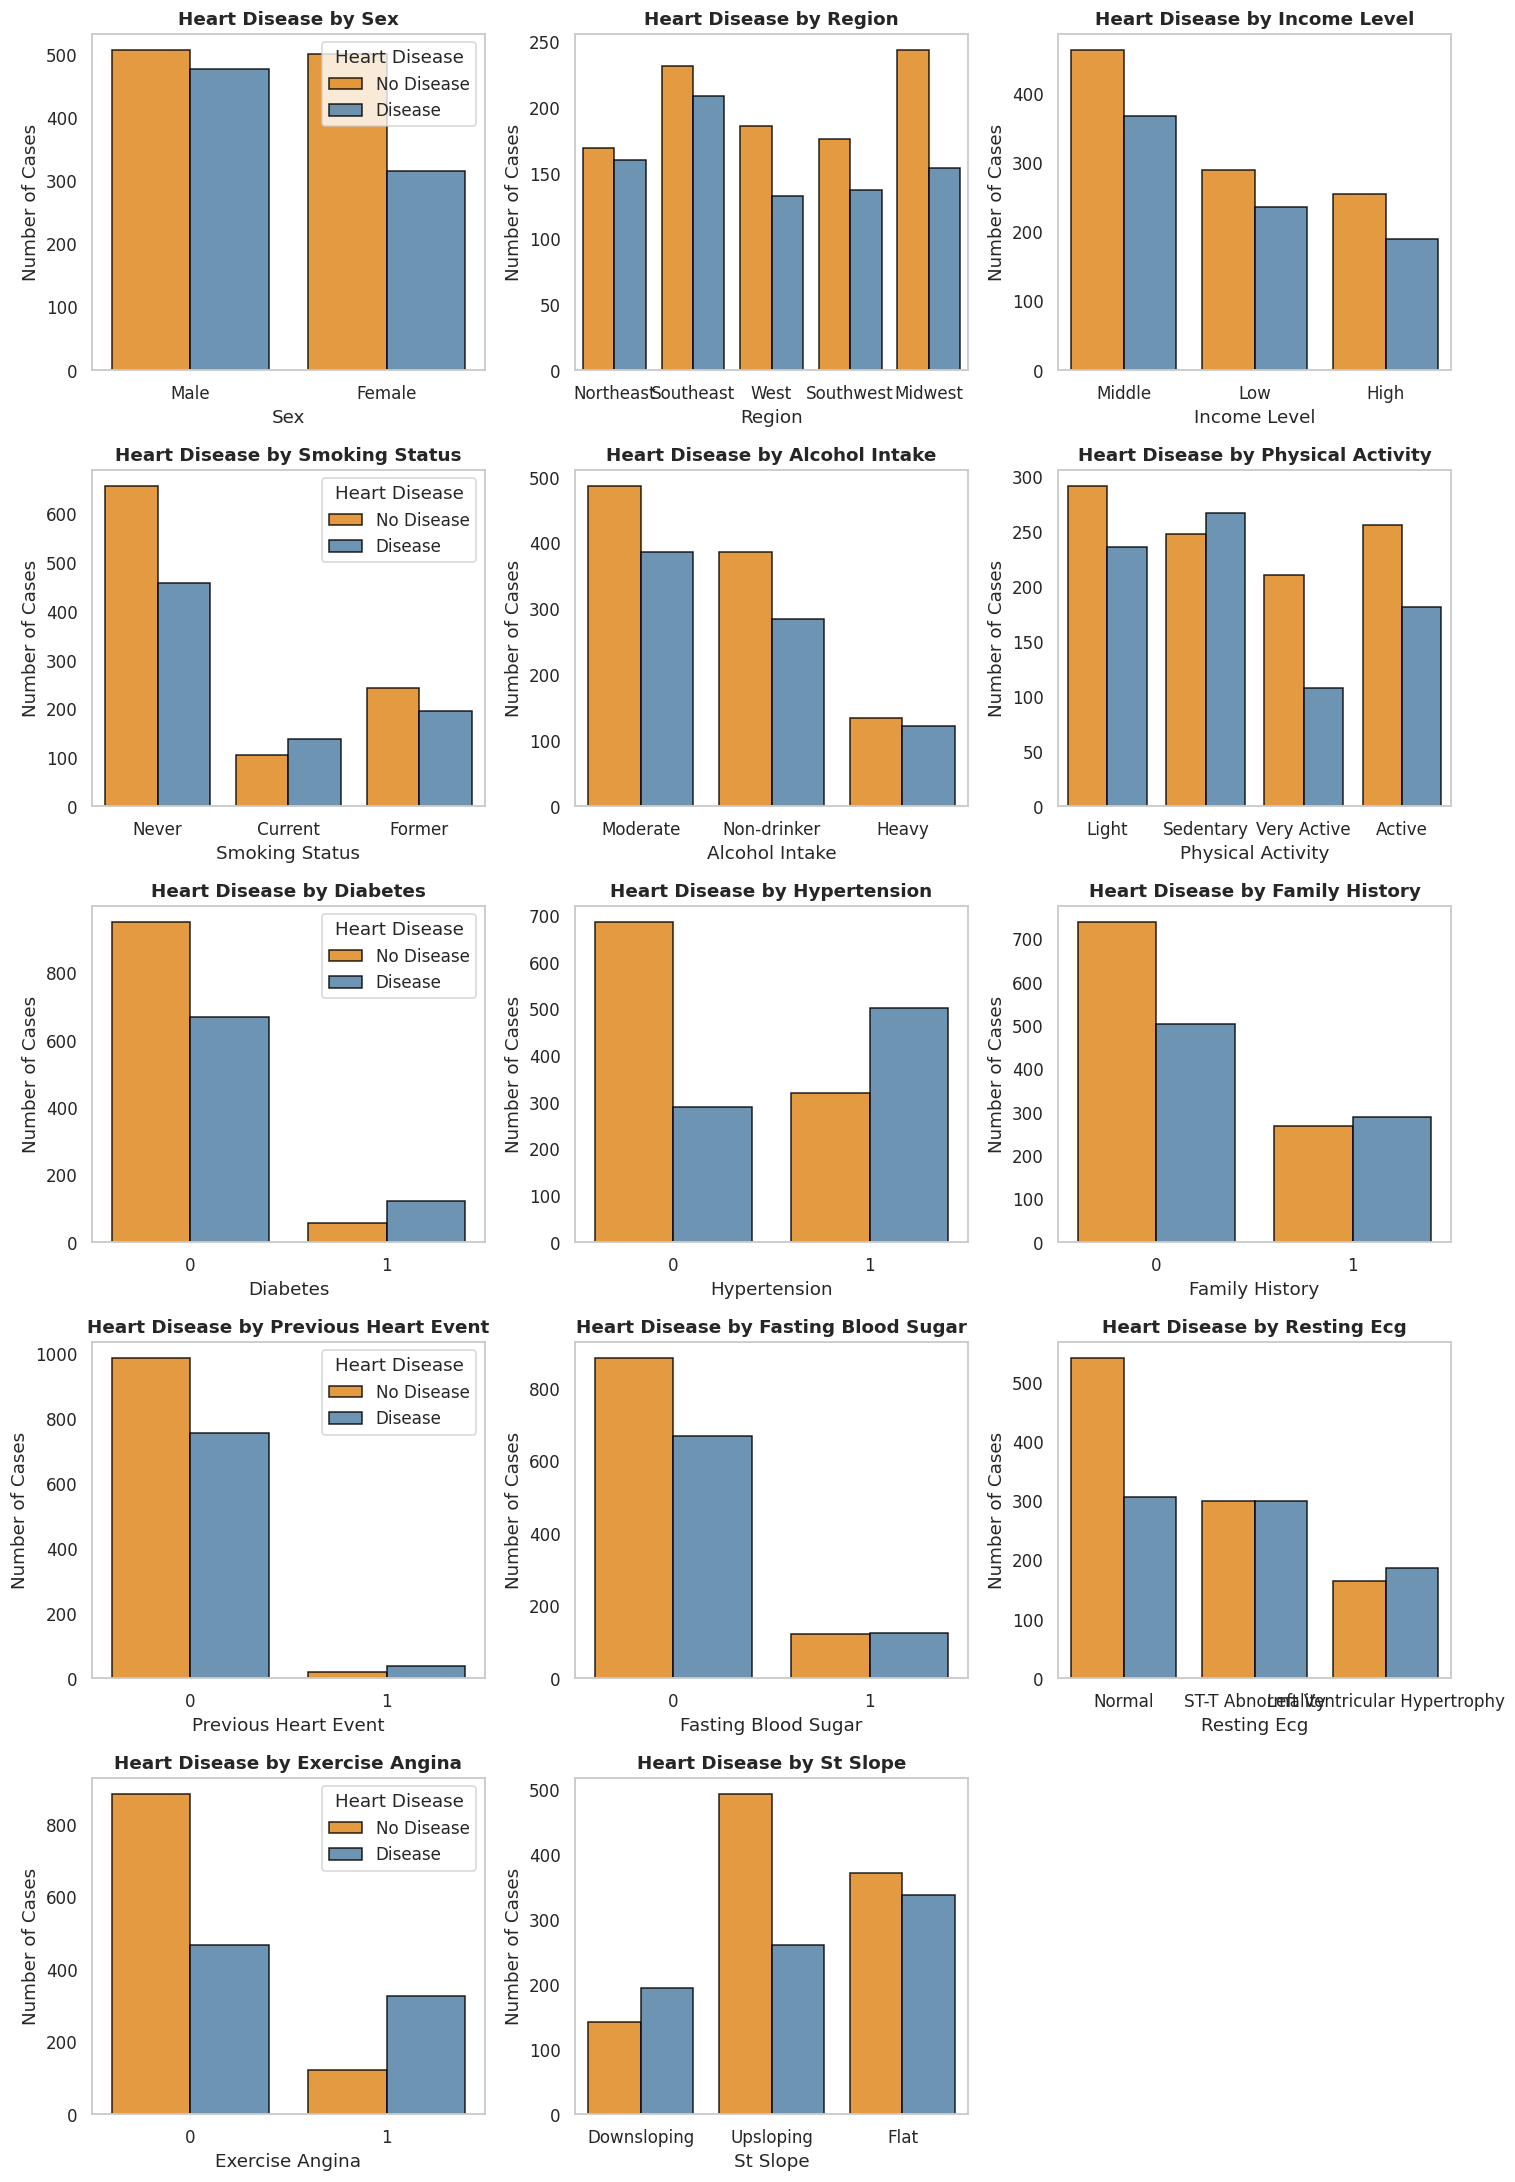

In [8]:
# ---- Initialize the subplot grid ----
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(14, 20))
axes = axes.flatten()

# ---- Loop through each variable and plot the categorical counts
for i, var in enumerate(categorical_vars):
    sns.countplot(data=train, x=var, hue="heart_disease", palette={0: "darkorange", 1: "steelblue"}, alpha=0.85, edgecolor="black", linewidth=1, ax=axes[i])

    axes[i].set_title(f"Heart Disease by {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Number of Cases")

    legend = axes[i].get_legend()
    legend.set_title("Heart Disease")
    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease")
    else:
        axes[i].get_legend().remove()

# ---- Hide the final empty subplot (15th slot) since we only have 14 variables ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

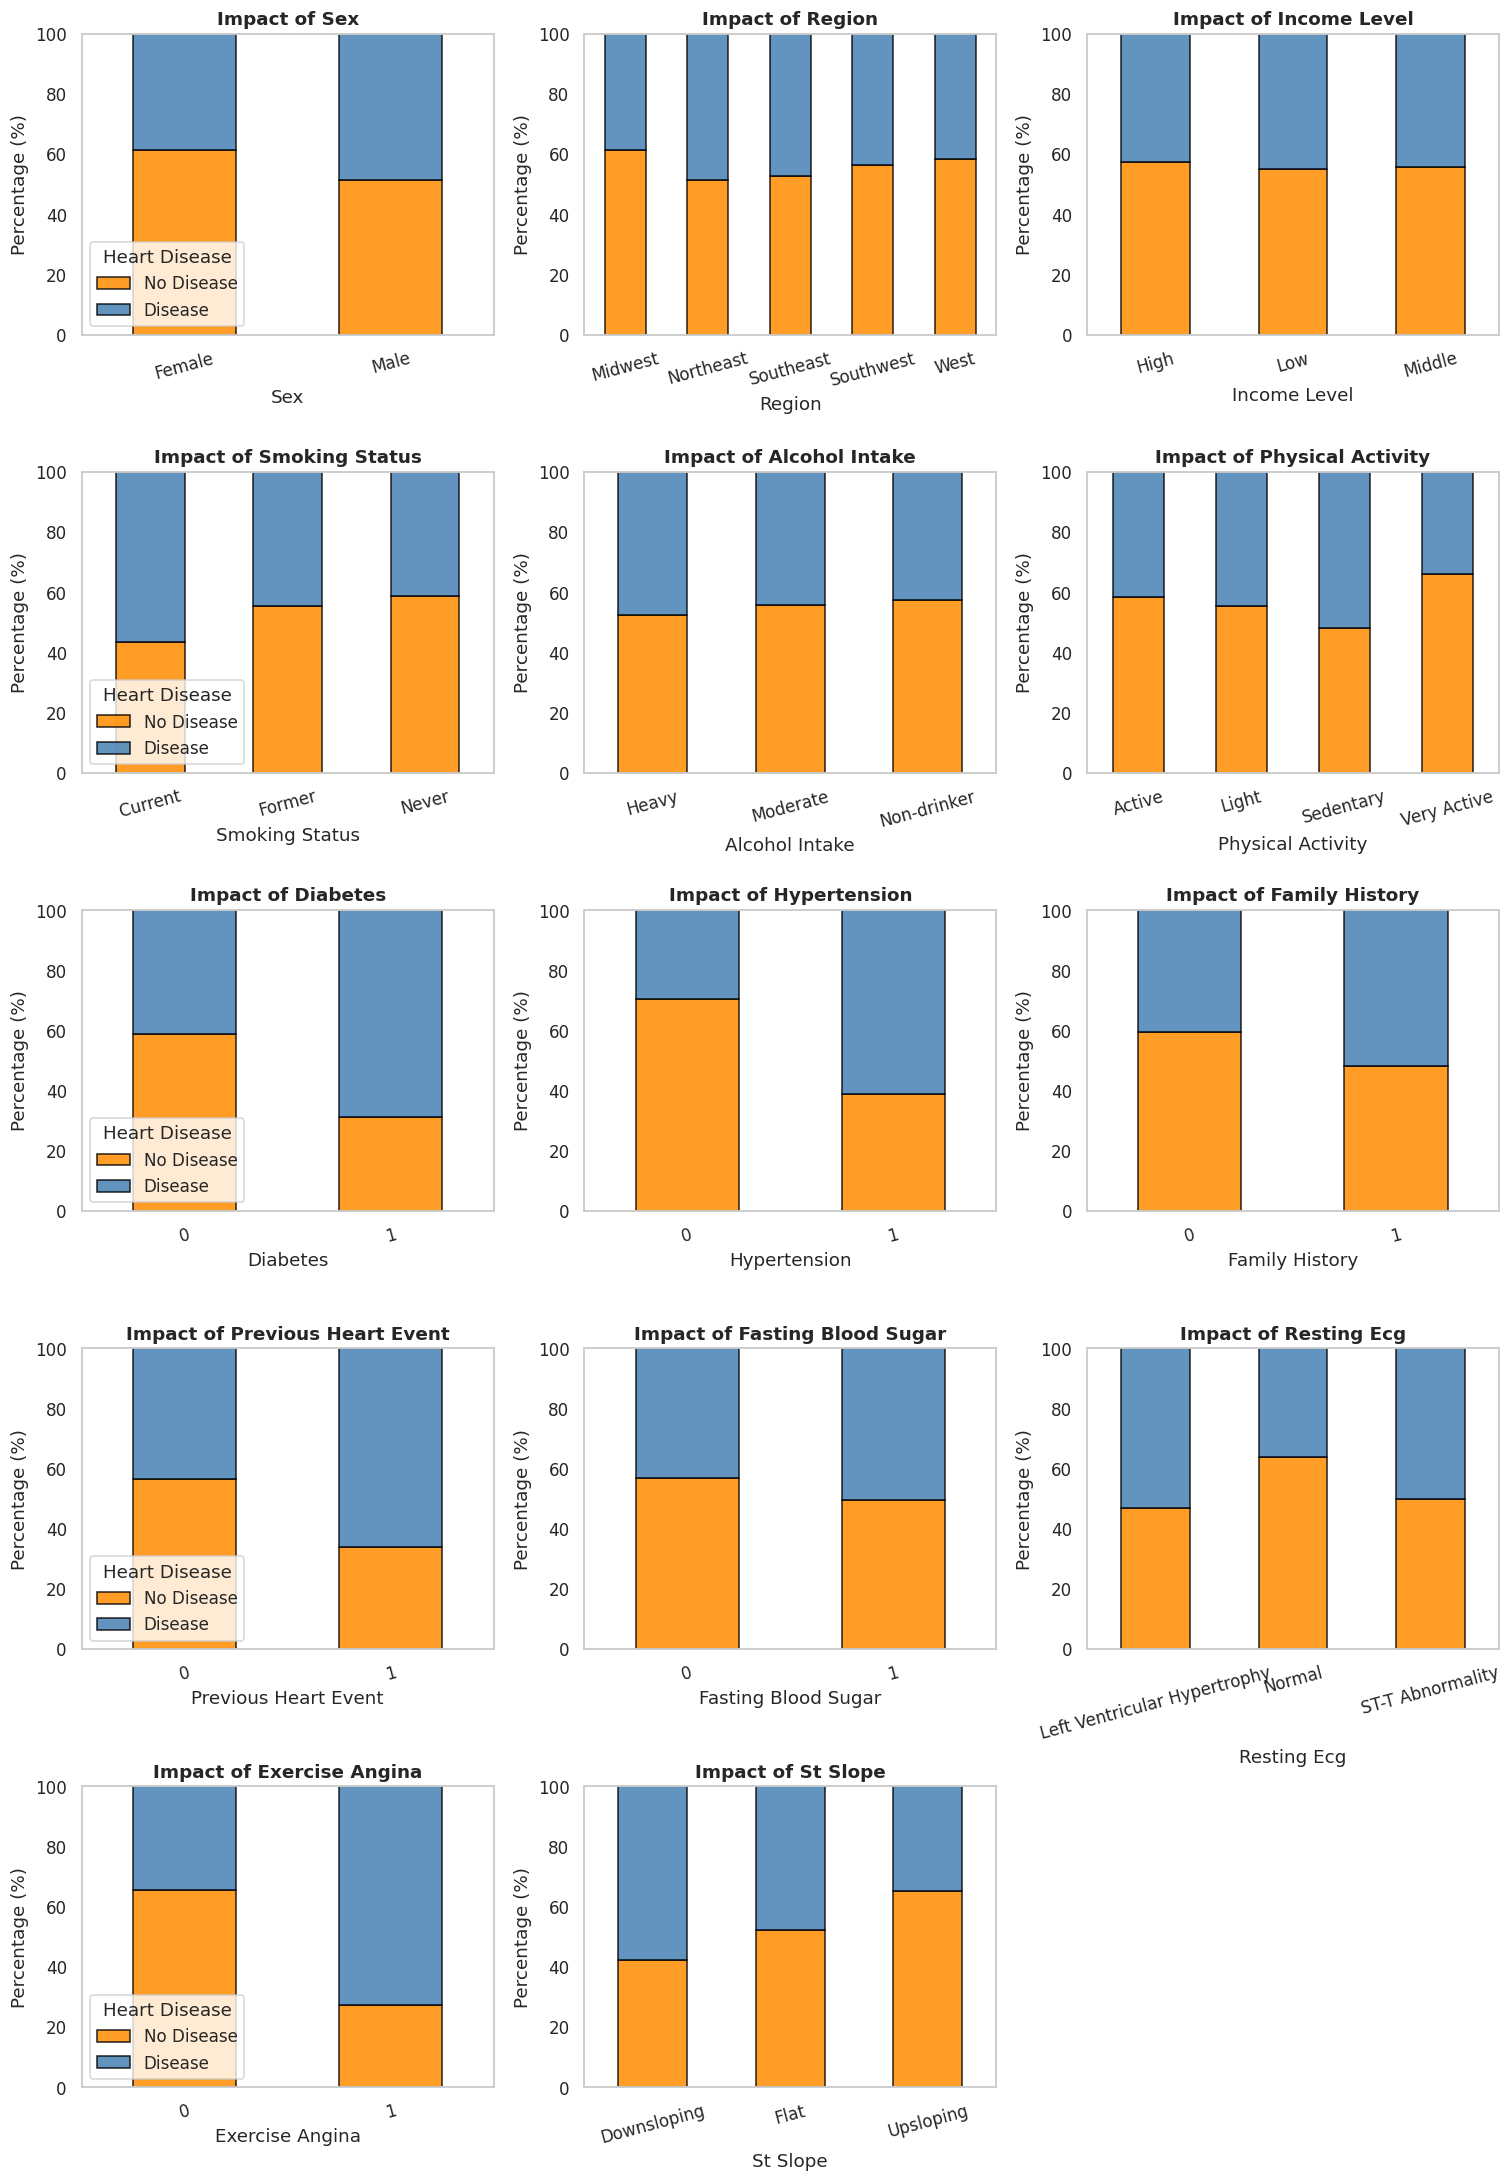

In [9]:
# ---- Setup the subplot grid (5 rows, 3 columns)   ----
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(14,20))
axes = axes.flatten()

# ---- Calculate percentages and plot  ----
for i, var in enumerate(categorical_vars):
    # Cross-tabulate and normalize by row to get percentages (0.0 to 1.0)
    crosstab_pct = pd.crosstab(train[var], train['heart_disease'], normalize='index') * 100

    # Plot stacked bars
    crosstab_pct.plot(kind='bar', stacked=True, ax=axes[i], color=["darkorange", "steelblue"], alpha=0.85, edgecolor="black")

    axes[i].set_title(f"Impact of {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Percentage (%)")
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis='x', labelrotation=15)

    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease", loc='lower left')
    else:
        axes[i].get_legend().remove()

# ---- Hide remaining empty subplot slots  ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

## Feature Engineering

In [10]:
# ---- Define updated list of categorical variables  ----
continuous_vars = [
    "age", "bmi", "stress_level",
    "resting_bp", "cholesterol", "st_depression",
    "avg_resting_hr"
]

categorical_vars = [
    "sex", "smoking_status", "alcohol_intake",
    "physical_activity", "diabetes", "hypertension",
    "family_history", "previous_heart_event"
]

In [11]:
# ---- Function to encode the datasets ----

def encode_data(data,message):

    # ---- Drop the unnecesary columns ----
    data_new=data.drop(columns=["region","income_level","st_slope","sleep_hours", "diet_quality","max_heart_rate","hrv_score","fasting_blood_sugar","resting_ecg","exercise_angina"])
    data_encoded = pd.get_dummies(data_new, columns=categorical_vars, drop_first=True)

    # ---- Convert any remaining boolean True/False outputs into clean 1s and 0s ----
    dummy_cols = [col for col in data_encoded.columns if col not in df.columns or col in categorical_vars]
    data_encoded[dummy_cols] = data_encoded[dummy_cols].astype(int)

    # ---- View your newly structured dataset ----
    print(f"\n--- {message} Encoded DataFrame Preview ---")
    print(f"Original shape: {data.shape}")
    print(f"Encoded shape: {data_encoded.shape}")
    print("\nNew columns added:")
    print(list(data_encoded.columns))

    return data_encoded

##Data split

In [12]:
# ---- Separate your features (X) and target variable (y) ----
train_encoded = encode_data(train,message="Training Data")
X = train_encoded.drop(columns=['heart_disease'])
y = train_encoded['heart_disease']

test_encoded = encode_data(test,message="Testing Data")
X_test = test_encoded.drop(columns=['heart_disease'])
y_test = test_encoded['heart_disease']

print(f"\nShape of the Training Sets: Input {X.shape}"," | ", f"Target {y.shape}")
print(f"Shape of the Test Sets: Input {X_test.shape}"," | ", f"Target {y_test.shape}")

# ---- Initialize the StandardScaler ----
scaler = StandardScaler()

# ---- Fit the scaler on the training data and transform both sets ----
X_train_scaled = X.copy()
X_test_scaled = X_test.copy()

# ---- Fit & transform the continuous columns on Train; transform only on Test ----
X_train_scaled[continuous_vars] = scaler.fit_transform(X[continuous_vars])
X_test_scaled[continuous_vars] = scaler.transform(X_test[continuous_vars])

# ---- Verify the scaled output scales ----
print("\n\n--- Scaling Verification ---")
print("Training Data:")
print("Original Age Mean:", X['age'].mean().round(2))
print("Scaled Age Mean (Should be ~0):", X_train_scaled['age'].mean().round(2))
print("Scaled Age Standard Deviation (Should be ~1):", np.float64(X_train_scaled['age'].std()).round(2))

print("\nTesting Data:")
print("Original Age Mean:", X_test['age'].mean().round(2))
print("Scaled Age Mean (Should be ~0):", X_test_scaled['age'].mean().round(2))
print("Scaled Age Standard Deviation (Should be ~1):", np.float64(X_test_scaled['age'].std()).round(2))



--- Training Data Encoded DataFrame Preview ---
Original shape: (1800, 26)
Encoded shape: (1800, 20)

New columns added:
['age', 'bmi', 'stress_level', 'resting_bp', 'cholesterol', 'st_depression', 'avg_resting_hr', 'heart_disease', 'sex_Male', 'smoking_status_Former', 'smoking_status_Never', 'alcohol_intake_Moderate', 'alcohol_intake_Non-drinker', 'physical_activity_Light', 'physical_activity_Sedentary', 'physical_activity_Very Active', 'diabetes_1', 'hypertension_1', 'family_history_1', 'previous_heart_event_1']

--- Testing Data Encoded DataFrame Preview ---
Original shape: (200, 26)
Encoded shape: (200, 20)

New columns added:
['age', 'bmi', 'stress_level', 'resting_bp', 'cholesterol', 'st_depression', 'avg_resting_hr', 'heart_disease', 'sex_Male', 'smoking_status_Former', 'smoking_status_Never', 'alcohol_intake_Moderate', 'alcohol_intake_Non-drinker', 'physical_activity_Light', 'physical_activity_Sedentary', 'physical_activity_Very Active', 'diabetes_1', 'hypertension_1', 'family

In [13]:
X_train_scaled.head()

,age,bmi,stress_level,resting_bp,cholesterol,st_depression,avg_resting_hr,sex_Male,smoking_status_Former,smoking_status_Never,alcohol_intake_Moderate,alcohol_intake_Non-drinker,physical_activity_Light,physical_activity_Sedentary,physical_activity_Very Active,diabetes_1,hypertension_1,family_history_1,previous_heart_event_1
0,0.348894,-0.152365,0.105605,1.014616,-0.226979,-0.441890,-0.667018,1,0,1,1,0,1,0,0,1,0,1,0
1,-1.021776,0.198135,0.559280,-1.732590,-0.879465,-0.828430,-1.368264,0,0,1,0,1,0,1,0,0,0,1,0
2,0.832660,2.245792,-0.348069,-0.109241,-0.121739,0.910999,1.004558,0,0,1,1,0,0,1,0,0,0,0,0
3,1.074543,1.397213,-0.348069,0.972992,-0.584794,-0.055350,0.091307,0,0,1,0,0,0,1,0,0,1,0,0
4,-1.908680,-1.499022,1.012955,-0.234114,0.678083,-0.925064,0.335928,0,0,0,0,1,0,1,0,0,0,1,0


## Traning and Testing the Models

In [14]:
"""#Saving the models
# 3. Load the model back at a later time
loaded_model = joblib.load('my_trained_model.joblib')

# 4. Use the loaded model to make predictions
predictions = loaded_model.predict(X)"""

"#Saving the models\n# 3. Load the model back at a later time\nloaded_model = joblib.load('my_trained_model.joblib')\n\n# 4. Use the loaded model to make predictions\npredictions = loaded_model.predict(X)"

--- TRAINING AND EVALUATING MODELS ---
Running Logistic_Regression...
Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Running Decision_Tree...
Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

Running Support_Vector_Machine...
Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========================= MODEL PERFORMANCE REPORT =========================
                        Accuracy  AUC Score  Precision  Recall  F1 Score  \
Logistic_Regression        0.710     0.7987     0.7019    0.73    0.7157   
Decision_Tree              0.540     0.5400     0.5455    0.48    0.5106   
KNN                        0.645     0.7248     0.6790    0.55    0.6077   
Naive_Bayes_Gaussian       0.690     0.7785     0.7159    0.63    0.6702   
Support_Vector_Machine     0.690     0.7705     0.6900    0.69    0.6900   

                        MCC Score  
Logistic_Regression        0.4203  
Decision_Tree              0.0806  
KNN                        0.2954  
Naive_Bayes_Gaussian       0.3828  
Support_Vector_Machine     0.3800  



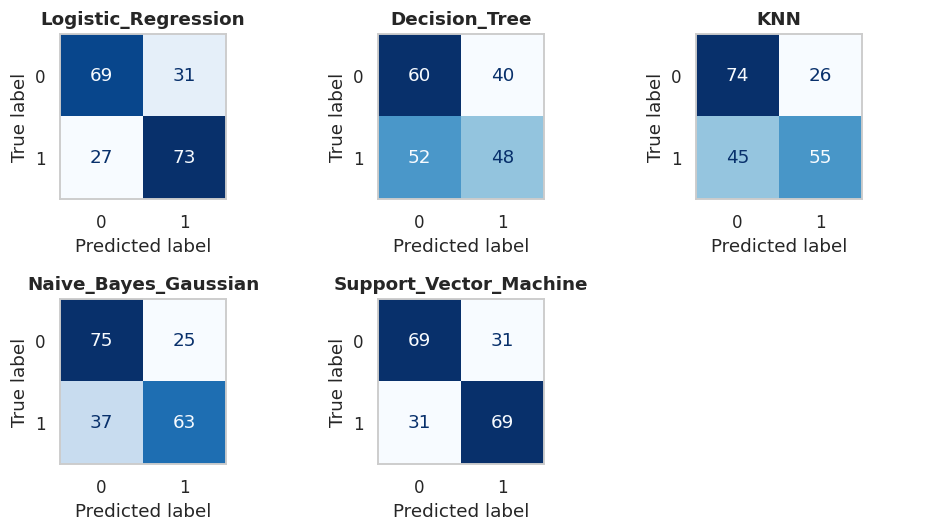

In [15]:
# ---- Initialize all 5 classifiers ----
models = {
    'Logistic_Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision_Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive_Bayes_Gaussian': GaussianNB(),
    'Support_Vector_Machine': SVC(probability=True, random_state=42)
    # (probability=True is required for calculation of exact AUC scores on SVM)
}

# ---- Setup structures to hold evaluation results ----
performance_results = {}

# ---- Set up a grid layout (2 rows, 3 columns to fit all 5 models cleanly) ----
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 5))
axes = axes.flatten()  # Convert grid to a 1D list for easier looping

print("--- TRAINING AND EVALUATING MODELS ---")

# ---- Loop through each model to train, predict, and evaluate ----#
for idx, (model_name, model_instance) in enumerate(models.items()):
    print(f"Running {model_name}...")

    # Train the model on scaled training features
    model_instance.fit(X_train_scaled, y)

    # Generate hard class predictions (0 or 1) for metrics and confusion matrices
    y_pred = model_instance.predict(X_test_scaled)

    # Generate predicted probabilities for the positive class (1) to get accurate AUC scores
    y_prob = model_instance.predict_proba(X_test_scaled)[:, 1]

    # Calculate all 6 core metrics requested
    performance_results[model_name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC Score': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'MCC Score': matthews_corrcoef(y_test, y_pred)
    }

    joblib.dump(model_instance, f'{model_name}.joblib')
    print("Model saved successfully!")
    files.download(f'{model_name}.joblib')

    # Generate and plot the visual Confusion Matrix on its assigned grid axis
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[idx],
        cmap='Blues',
        colorbar=False
    )
    axes[idx].set_title(model_name, fontsize=12, fontweight='bold')

# ---- Hide the unused 6th subplot axis slot ----
axes[-1].axis('off')

# ---- Display the comprehensive performance report table ----
metrics_df = pd.DataFrame(performance_results).T

print("\n========================= MODEL PERFORMANCE REPORT =========================")
print(metrics_df.round(4))
print("============================================================================\n")

# ---- Render the side-by-side charts ----#
plt.tight_layout()
plt.grid(False)
plt.show()

***Analysis of the Models and the winner:***

1. Logistic Regression (winner):
    - Highest overall accuracy: It successfully correctly classifies 71% of all cases.
    - Superior discriminative power: Its AUC score of 0.80 indicates a strong ability to distinguish between healthy individuals and those with heart disease.
    - Excellent Recall (0.73): In medical diagnostics, Recall is the most critical metric. You want to catch as many true heart disease cases as possible. A high recall means fewer patients with heart disease are missed (low False Negatives).
    - Strongest balance (F1 and MCC): Its F1-score (0.72) and MCC (0.42) are the highest in the chart, proving that its predictions are balanced and reliable, rather than heavily favoring one outcome.
    - Summary: Logistic Regression excels by modeling the log-odds of the target variable as a linear combination of predictors, making it highly effective for multi-feature clinical datasets. By converting feature weights into well-calibrated probabilities, it balances precision and recall to achieve the highest overall predictive performance.

2. Naive Bayes - Gaussian:

    - Accuracy (0.69): The model correctly classifies 69% of all patients in the test set.
    - AUC Score (0.78): It indicates a 78% probability that the model will rank a randomly selected heart disease patient as higher risk than a healthy patient.
    - Precision (0.72): This is the highest precision across all 5 models. It means that out of everyone this model flags as having heart disease, 72% actually do.
    - Recall (0.63): This is its major clinical flaw. It only catches 63% of true heart disease cases. It completely misses 37% of sick patients (high False Negatives), sending them home undiagnosed.
    - F1 Score (0.67): Reflects the imbalance between its high precision and lagging recall.
    - MCC Score (0.38): A moderate positive correlation. It confirms the model has real predictive capability, but is held back by its tendency to miss cases.
    - Summary: The Naive Bayes classifier assumes strict feature independence, ignoring natural clinical correlations among variables like age, blood pressure, and cholesterol. This structural limitation causes the model to adopt an overly conservative classification threshold, yielding high precision but a high miss rate (low recall).

3. Support Vector Machine:

    - Accuracy (0.69): It successfully matches Naive Bayes, accurately sorting 69% of the overall patient pool.
    - AUC Score (0.77): Shows a 77% separation efficiency between healthy and diseased patients, proving it is highly stable.
    - Precision (0.69) & Recall (0.69): The model is perfectly symmetrical. It balances its errors equally, catching 69% of sick patients while maintaining a 69% accuracy rate on those positive flags.
    - F1 Score (0.69): Because precision and recall are identical, the F1 score lands exactly at 0.69, showing no bias toward over-predicting or under-predicting the disease.
    - MCC Score (0.38): Tied with Naive Bayes, proving it is a reliable, stable classifier that handles the data cleanly without erratic behavior.
    - Summary: Prior standardization via StandardScaler allowed the SVM to establish a clean geometric hyperplane to separate the patient cohorts. By optimizing for spatial distance, the model scales balanced metrics symmetrically, though it remains less effective than the probabilistic framework of Logistic Regression.

4. K-Nearest Neighbors:

    - Accuracy (0.65): The accuracy is starting to decrease into Problematic region.
    - AUC Score (0.72): A fair but noticeably weaker ability to distinguish between sick and healthy individuals compared to the top models.
    - Precision (0.68): When it flags a patient, it is reasonably confident (68% correct).
    - Recall (0.55): Clinically unacceptable. It catches only 55% of heart disease cases, and misses nearly half (45%) of the sick patients, making it highly unsafe for medical screening.
    - F1 Score (0.61): Is Low due to the massive gap between its precision and its poor recall.
    - MCC Score (0.30): A weak positive correlation, indicating that the model's predictions are starting to drift closer to random guessing.
    - Summary: The KNN algorithm degrades due to the "curse of dimensionality," as one-hot encoding 14 categorical features expands the dataset into a sparse, high-dimensional space. This spatial expansion distorts geometric distance metrics, preventing the model from accurately identifying true patient similarities.

5. Decision Tree Classifier:

    - Accuracy (0.54): At 54%, this model is performing barely better than a random coin toss (50%).
    - AUC Score (0.54): Confirms that the model has almost zero discriminative power. It cannot reliably separate a sick patient from a healthy one.
    - Precision (0.55): Out of all patients flagged with heart disease, nearly half (45%) are false alarms.
    - Recall (0.48): It misses 52% of actual heart disease cases, failing to catch more than half of the sick population.
    - F1 Score (0.51): Poor overall performance across the board.
    - MCC Score (0.08): An MCC of 0.08 is statistically near 0, proving there is virtually no true relationship between this model's predictions and actual medical reality.
    - Summary: A standalone Decision Tree is highly unstable and prone to overfitting, building rigid boundaries tailored exclusively to training data idiosyncrasies. When exposed to unseen test data, these fragile decision pathways fail to generalize, resulting in erratic, low-utility classifications.